# EDA: AgERA5 daily series and cross-checks

Loads the outputs of `pipelines/02b_eda_agera5.py`. AgERA5 is derived from ERA5 reanalysis; agreement with ERA5-Land is a consistency check, not an independent validation.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
P = ROOT / "data" / "processed"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## Coverage, NaN, cloud range and grid offset

In [2]:
pd.read_csv(P / "eda_agera5" / "coverage.csv", index_col=0).T

point_id,el_alto,oruro,patacamaya,calamarca,caracollo,corocoro,charana,huanuni
first_date,1984-12-31,1984-12-31,1984-12-31,1984-12-31,1984-12-31,1984-12-31,1984-12-31,1984-12-31
last_date,2026-10-25,2026-10-25,2026-10-25,2026-10-25,2026-10-25,2026-10-25,2026-10-25,2026-10-25
days,15274,15274,15274,15274,15274,15274,15274,15274
expected_days,15274,15274,15274,15274,15274,15274,15274,15274
non_daily_steps,0,0,0,0,0,0,0,0
duplicates,0,0,0,0,0,0,0,0
nan_cloud_cover_24h,0,0,0,0,0,0,0,0
nan_tmin_night_k,0,0,0,0,0,0,0,0
nan_rh_15h,0,0,0,0,0,0,0,0
cloud_below_0,0,0,0,0,0,0,0,0


## Cloud cover seasonal cycle

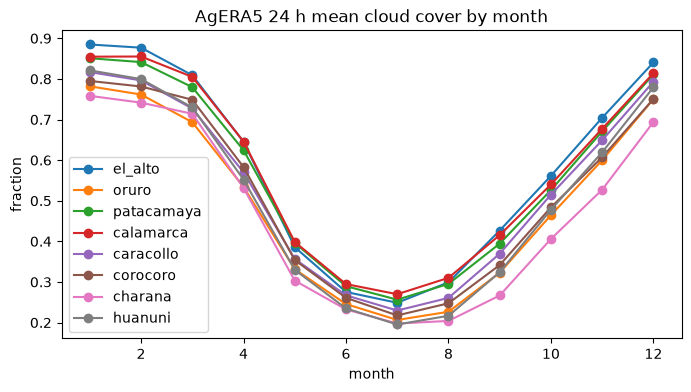

In [3]:
cc = pd.read_csv(P / "eda_agera5" / "cloud_cover_by_month.csv", index_col=0)
ax = cc.plot(marker="o", figsize=(8, 4), title="AgERA5 24 h mean cloud cover by month")
ax.set_ylabel("fraction"); plt.show()

## Cross-checks against ERA5-Land

The night-time minimum dated D covers the night ending on the morning of D; the two correlation columns compare both alignments.

In [4]:
pd.read_csv(P / "eda_agera5" / "crosschecks.csv", index_col=0).round(3)

,n_days,tmin_corr_night_ending,tmin_corr_night_starting,tmin_bias_c,tmin_mae_c,frost_flag_agreement,frost_rate_agera5,frost_rate_era5land,rh_corr,rh_bias_pct,rh_mae_pct
point_id,,,,,,,,,,,
el_alto,14974,0.903,0.805,-0.560,0.982,0.900,0.224,0.177,0.883,-8.234,10.550
oruro,14974,0.939,0.846,0.095,0.844,0.907,0.221,0.199,0.962,-2.195,5.325
patacamaya,14974,0.923,0.814,0.016,0.956,0.907,0.336,0.337,0.932,5.017,7.055
calamarca,14974,0.941,0.820,-0.309,0.931,0.917,0.376,0.352,0.915,4.141,7.285
caracollo,14974,0.928,0.823,-0.207,0.983,0.921,0.206,0.215,0.956,-4.692,7.189
corocoro,14974,0.953,0.830,1.202,1.730,0.880,0.395,0.491,0.965,3.390,5.249
charana,14974,0.915,0.785,1.351,1.805,0.873,0.549,0.627,0.957,1.368,5.625
huanuni,14974,0.913,0.808,-0.624,1.009,0.889,0.420,0.361,0.964,1.717,5.835


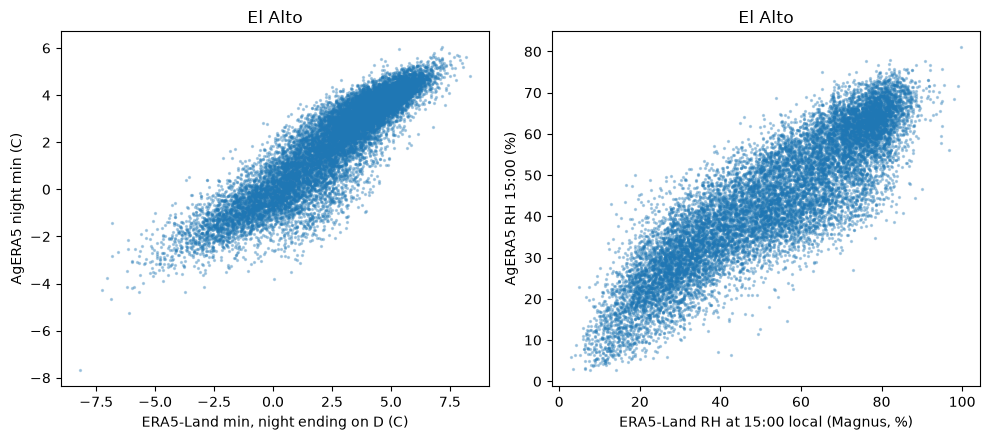

In [5]:
d = pd.read_parquet(P / "eda_agera5" / "daily_crosscheck.parquet")
el = d[d["point_id"] == "el_alto"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].scatter(el["era5land_min_night_ending_c"], el["agera5_tmin_c"], s=2, alpha=0.3)
axes[0].set(xlabel="ERA5-Land min, night ending on D (C)", ylabel="AgERA5 night min (C)", title="El Alto")
axes[1].scatter(el["era5land_rh_19utc"], el["agera5_rh15"], s=2, alpha=0.3)
axes[1].set(xlabel="ERA5-Land RH at 15:00 local (Magnus, %)", ylabel="AgERA5 RH 15:00 (%)", title="El Alto")
plt.tight_layout(); plt.show()